In [1]:
import numpy as np
from scipy.io import loadmat
import warnings
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy.optimize import curve_fit

In [2]:
!pip install pandas
!pip install resonator_tools

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root, least_squares
from scipy.special import ellipk
from scipy.constants import mu_0, epsilon_0
from resonator_tools import circuit

In [4]:
import os
os.chdir(r"C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-003")   # paste your copied path here
print(os.getcwd())
print(os.listdir())

C:\Users\chowdhf4\.vscode\Tunable-Coupler\TC-Main-003
['Current_v3.mat', 'f0_guess.mat', 'f0_guess_v2.mat', 'f0_guess_v3.mat', 'f0_guess_v4.mat', 'f0_guess_v5.mat', 'Freq.mat', 'Freq_v2.mat', 'I1.mat', 'S21_complex_wbg_wtd.mat', 'S21_corr_complex.mat', 'S21_corr_complex_v2.mat', 'TC-Main-003_fit-v1.ipynb', 'TC-Main-003_fit-v2.ipynb']


In [64]:
# Files
File_Complex     = 'S21_corr_complex_v2.mat'
FILE_FREQ        = 'Freq.mat'
FILE_CURRENT     = 'I1.mat'
File_F0_Guess    = 'f0_guess_v4.mat'

def mat_to_1d_vector(d):
    for k, v in d.items():
        if k.startswith('__'): continue
        arr = np.asarray(v).squeeze()
        if arr.ndim == 1 and np.isrealobj(arr):
            return arr
    raise ValueError("No 1D array found in .mat file")

Mat_Freq     = loadmat(FILE_FREQ, squeeze_me=True)
Mat_Current  = loadmat(FILE_CURRENT, squeeze_me=True)
Mat_Complex  = loadmat(File_Complex, squeeze_me=True)
Mat_F0_Guess = loadmat(File_F0_Guess, squeeze_me=True)
Mat_F0_Guess_v2 = loadmat('f0_guess_v5.mat', squeeze_me=True)
S21_Complex_full = Mat_Complex['S21_corrected'] 
Freq = Mat_Freq['Freq_lp']
I1_full  = Mat_Current['I1']
f0_guess = Mat_F0_Guess['dips']
f0_guess_v2 = Mat_F0_Guess_v2['dips']
#Mat_Complex

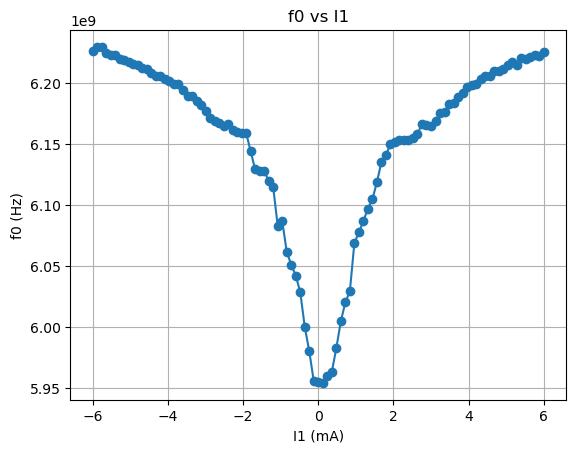

In [65]:
plt.plot(I1_full, f0_guess, '-o')
# plt.plot(I1_full, f0_guess_v2, '-o')
plt.xlabel('I1 (mA)')
plt.ylabel('f0 (Hz)')
plt.title('f0 vs I1')
plt.grid()
plt.show()

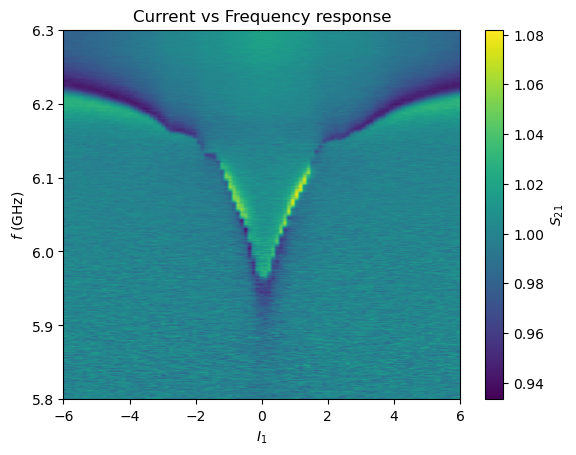

In [8]:
plt.imshow(np.abs(S21_Complex_full), aspect='auto', origin='lower', extent=[I1_full[0], I1_full[-1], Freq[0]/1e9, Freq[-1]/1e9])
plt.colorbar(label=r'$S_{21}$')
plt.xlabel(r'$I_1$')
plt.ylabel(r'$f$ (GHz)')
plt.title(r'Current vs Frequency response')
plt.show()

I1=-1.32 mA: f0=6119499999.999999 Hz, i=39


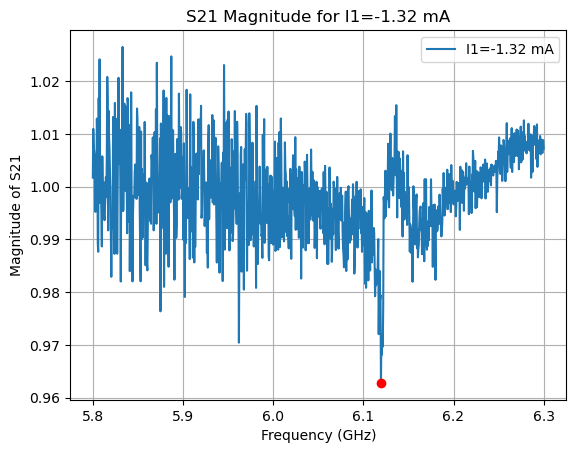

I1=-1.2 mA: f0=6114500000.000000 Hz, i=40


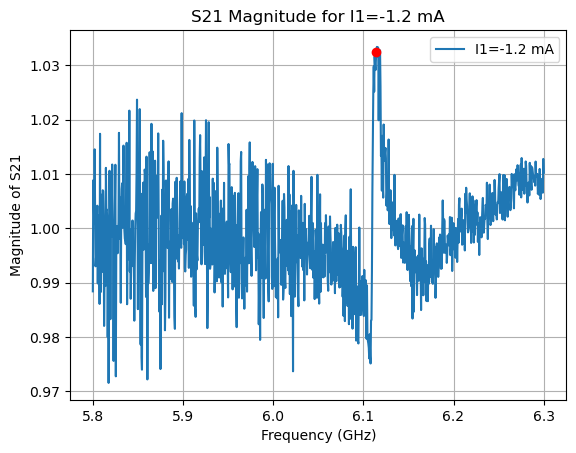

I1=-1.08 mA: f0=6083000000.000000 Hz, i=41


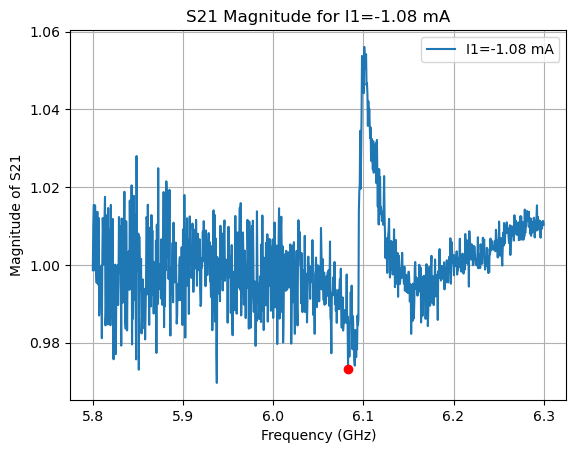

I1=-0.96 mA: f0=6087000000.000000 Hz, i=42


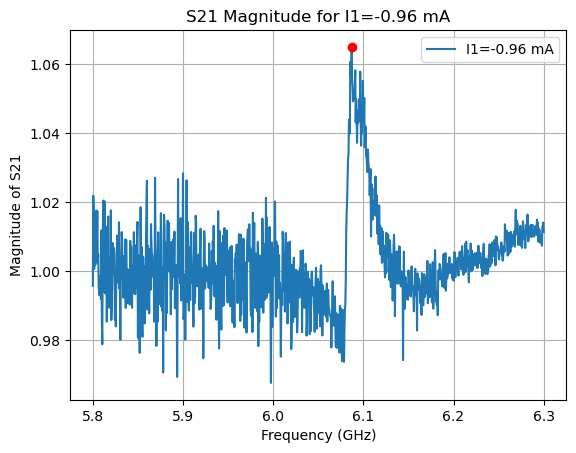

I1=-0.84 mA: f0=6061500000.000000 Hz, i=43


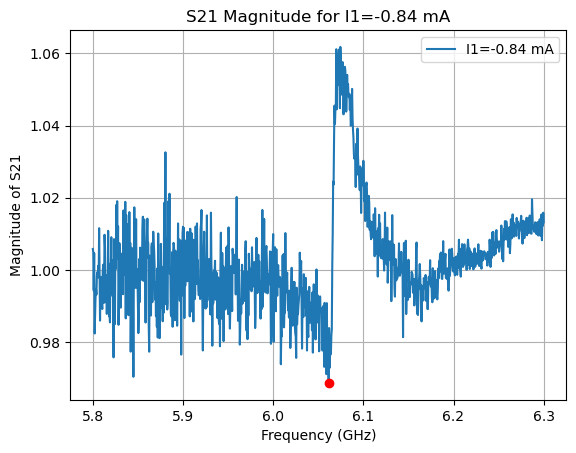

I1=-0.72 mA: f0=6051000000.000000 Hz, i=44


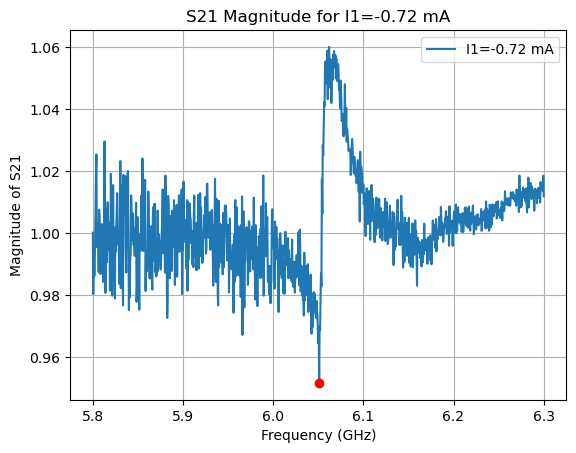

I1=-0.6 mA: f0=6042000000.000000 Hz, i=45


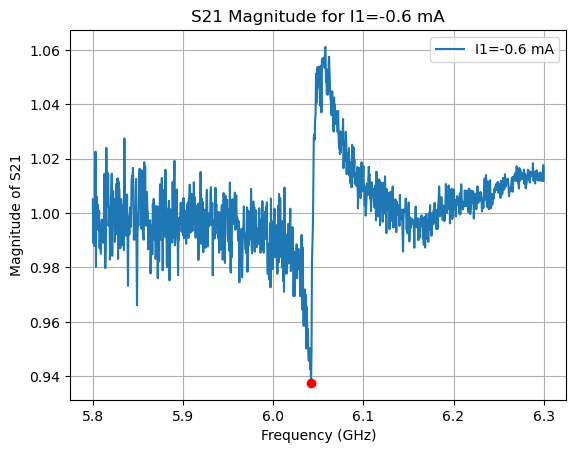

I1=-0.48 mA: f0=6028500000.000000 Hz, i=46


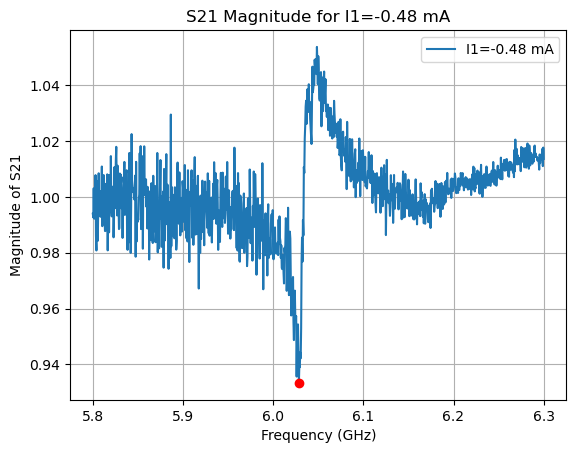

I1=-0.36 mA: f0=6000000000.000000 Hz, i=47


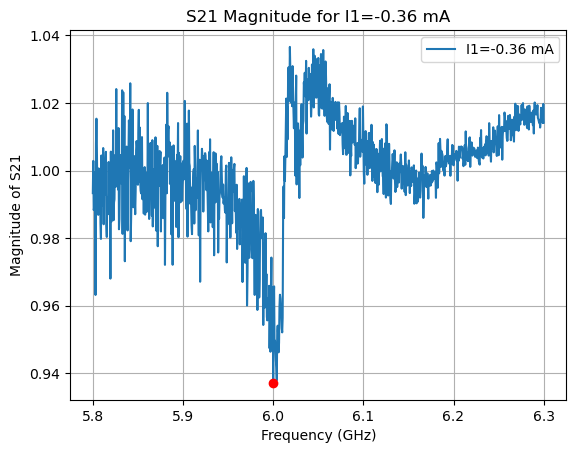

I1=-0.24 mA: f0=5980000000.000000 Hz, i=48


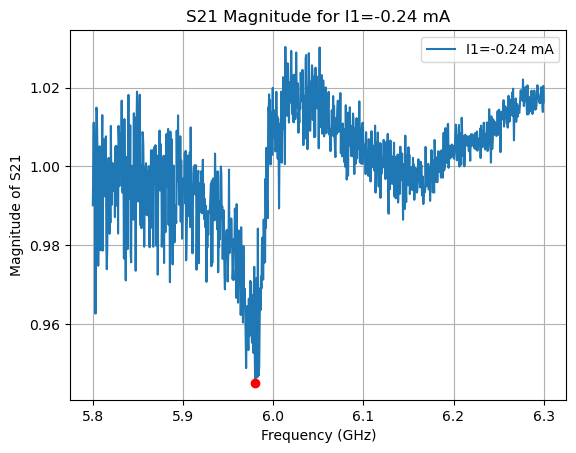

I1=-0.12 mA: f0=5955500000.000000 Hz, i=49


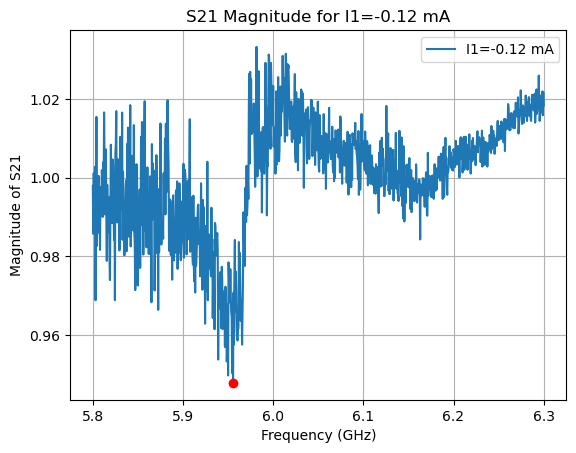

I1=0 mA: f0=5954499999.999999 Hz, i=50


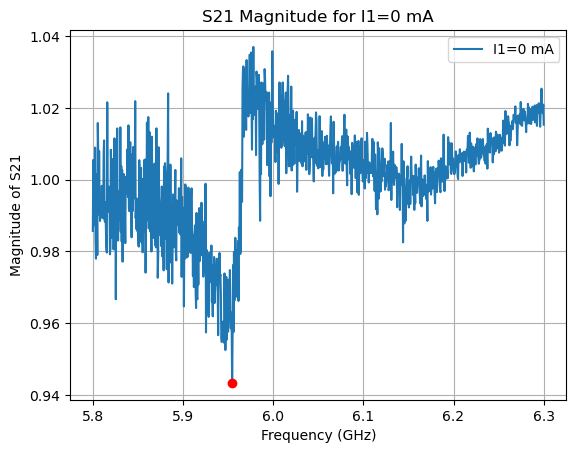

I1=0.12 mA: f0=5954000000.000000 Hz, i=51


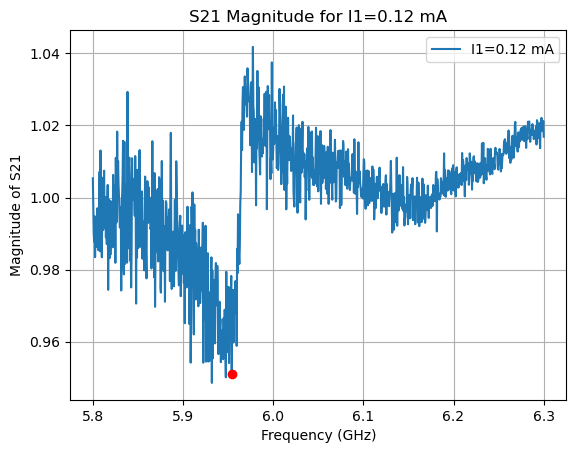

I1=0.24 mA: f0=5959500000.000000 Hz, i=52


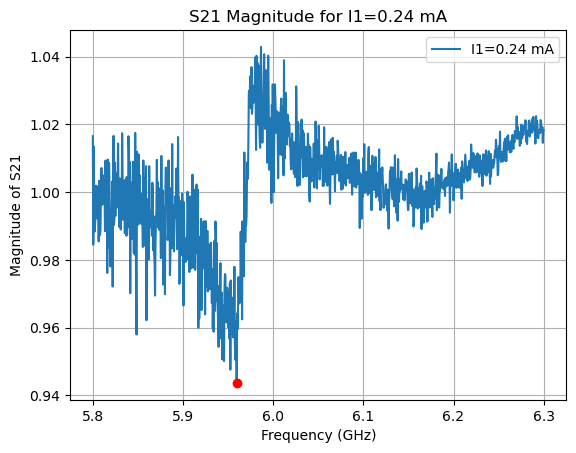

I1=0.36 mA: f0=5963000000.000000 Hz, i=53


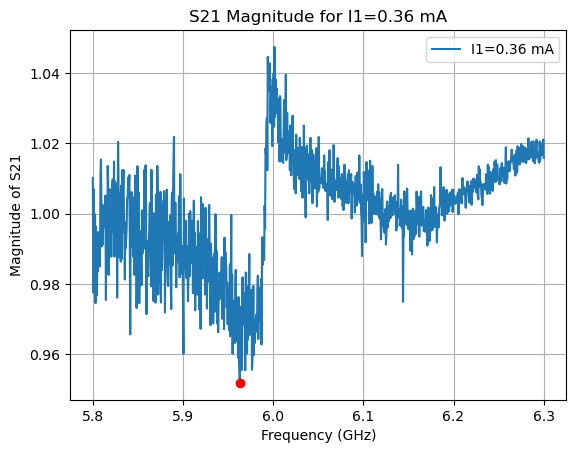

I1=0.48 mA: f0=5982500000.000000 Hz, i=54


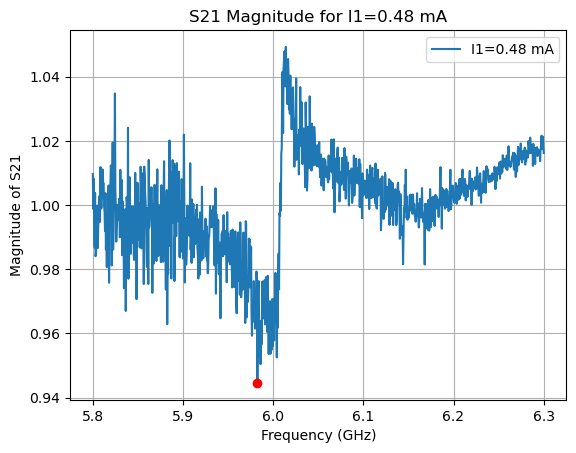

I1=0.6 mA: f0=6004500000.000000 Hz, i=55


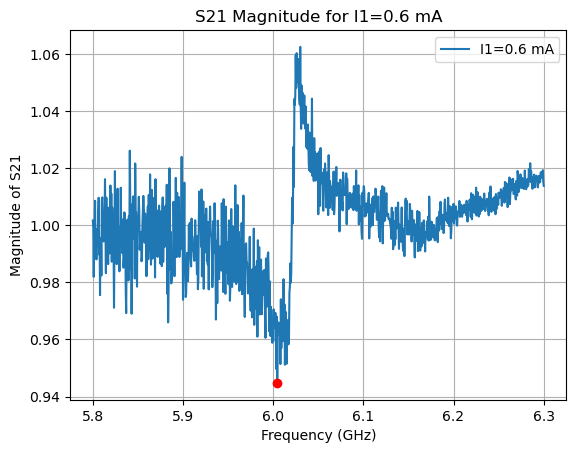

I1=0.72 mA: f0=6020000000.000000 Hz, i=56


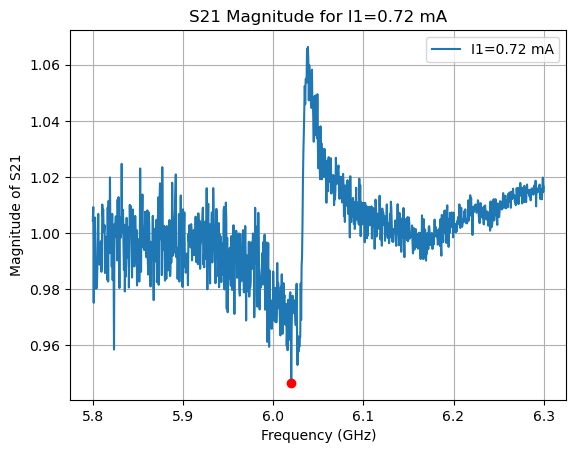

I1=0.84 mA: f0=6029000000.000000 Hz, i=57


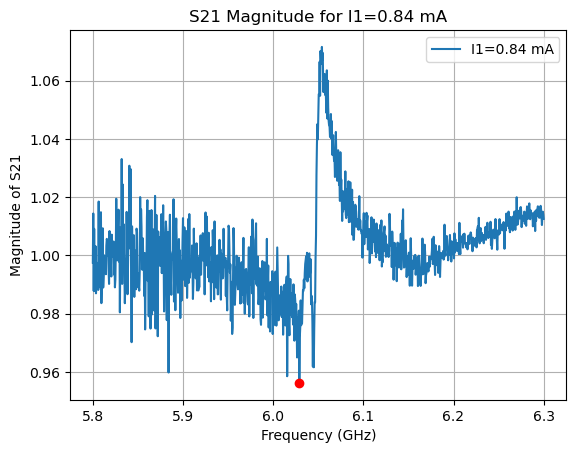

I1=0.96 mA: f0=6068500000.000000 Hz, i=58


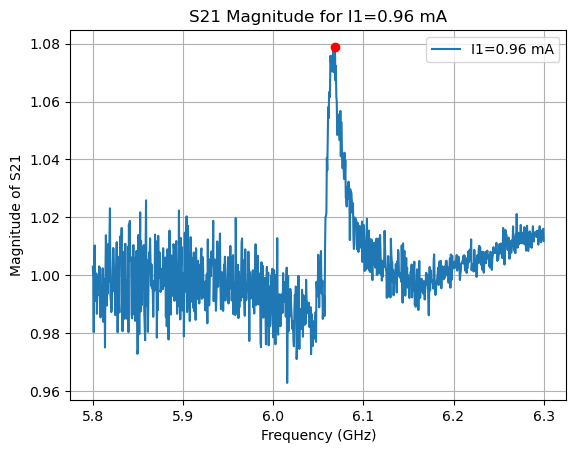

I1=1.08 mA: f0=6077500000.000000 Hz, i=59


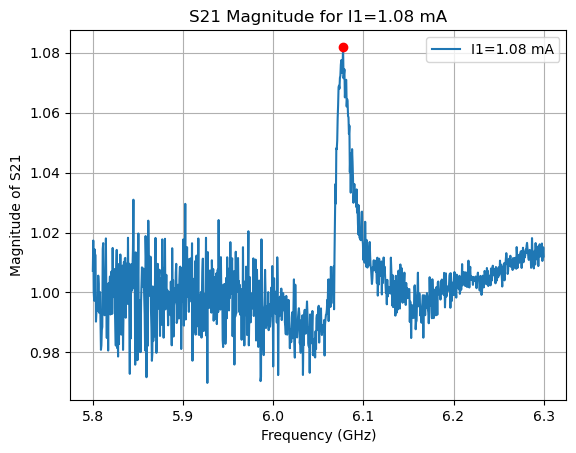

I1=1.2 mA: f0=6086500000.000000 Hz, i=60


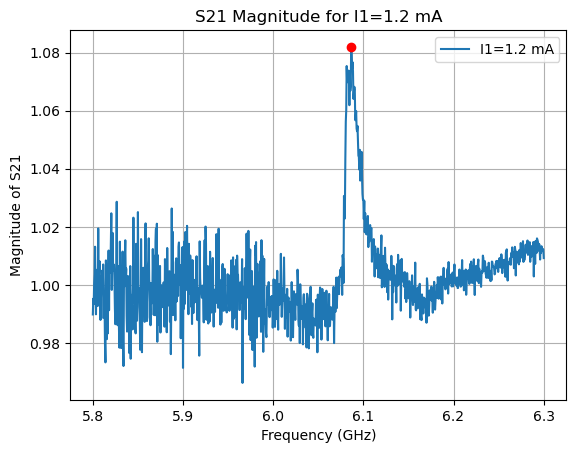

I1=1.32 mA: f0=6097000000.000000 Hz, i=61


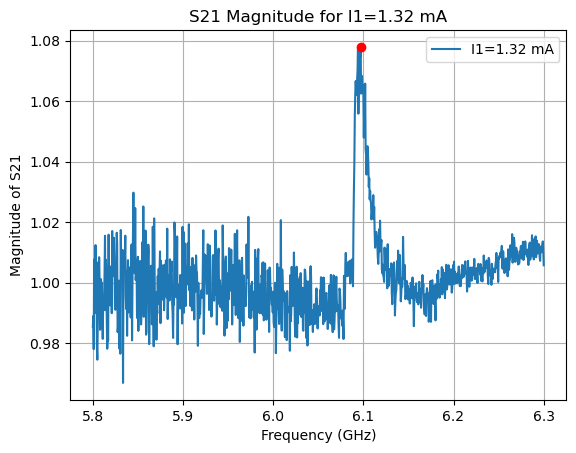

I1=1.44 mA: f0=6104500000.000000 Hz, i=62


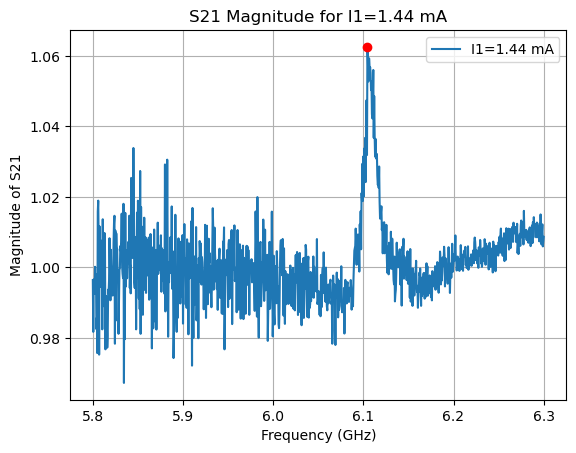

I1=1.56 mA: f0=6118500000.000000 Hz, i=63


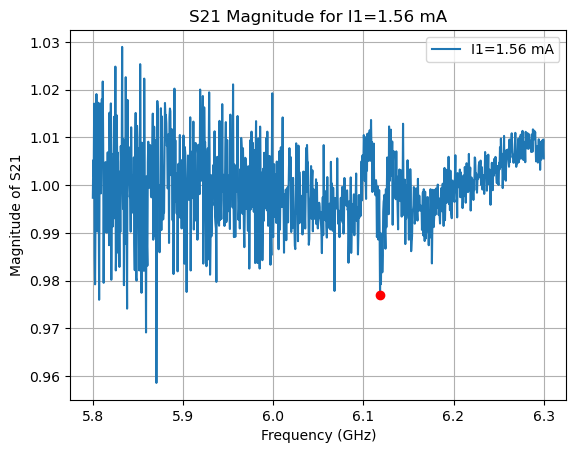

I1=1.68 mA: f0=6135000000.000000 Hz, i=64


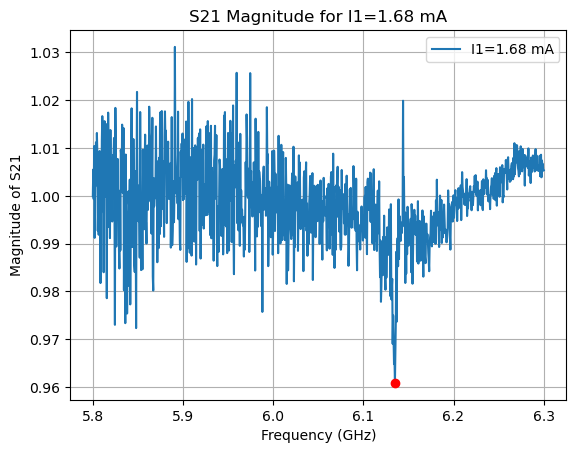

In [34]:
for i in range(39, 65, 1):
    S21_mag = np.abs(S21_Complex_full[:, i])

    plt.figure()
    line, = plt.plot(Freq/1e9, S21_mag, label=f'I1={I1_full[i]:.3g} mA')

    # Mark f0_guess on the curve
    f0 = f0_guess[i]  # Hz
    idx = np.argmin(np.abs(Freq - f0))  # nearest frequency index
    plt.plot(Freq[idx]/1e9, S21_mag[idx], 'o', color='r', markersize=6)

    print(f"I1={I1_full[i]:.3g} mA: f0={f0:.6f} Hz, i={i}")
    plt.xlabel('Frequency (GHz)')
    plt.ylabel('Magnitude of S21')
    plt.title(f'S21 Magnitude for I1={I1_full[i]:.3g} mA')
    plt.grid()
    plt.legend()
    plt.show()




In [70]:
fit_results_dict = {}
ports_dict = {}   # optional, if you want to re-plot a specific trace later without refitting
# window_halfwidth = 199e6 
# for i in range(40,43,1):
#     f0_guess[i] = f0_guess[44]
# for i in range(58,63,1):
#     f0_guess[i] = f0_guess[57]
# for i in range(S21_Complex_full.shape[1]):
#     if i  > 39 and i <  66:
#         window_halfwidth = 200e6
#     # elif i > 56 and i <  66:
#     #     window_halfwidth = 10e6
#     else:
#         window_halfwidth = 100e6

#     lower_bound = f0_guess[i] - window_halfwidth
#     upper_bound = f0_guess[i] + window_halfwidth
#     mask = (Freq >= lower_bound) & (Freq <= upper_bound)
#     f_sub = Freq[mask]
#     s_sub = S21_Complex_full[mask, i]

#     port_i = circuit.notch_port(f_sub, s_sub)
#     try:
#         port_i.autofit(electric_delay=0, fr_guess=f0_guess[i], Ql_guess=500)
#         fit_results_dict[i] = port_i.fitresults
#         ports_dict[i] = port_i
#     except Exception as e:
#         print(f"I1={I1_full[i]:.3g} mA: fit failed ({e})")
#         fit_results_dict[i] = None

last_good_Ql = 1000
for i in range(S21_Complex_full.shape[1]):
    if i  > 39 and i <  66:
        window_halfwidth = 200e6
    # elif i > 56 and i <  66:
    #     window_halfwidth = 10e6
    else:
        window_halfwidth = 100e6

    lower_bound = f0_guess[i] - window_halfwidth
    upper_bound = f0_guess[i] + window_halfwidth
    mask = (Freq >= lower_bound) & (Freq <= upper_bound)
    f_sub = Freq[mask]
    s_sub = S21_Complex_full[mask, i]
    port_i = circuit.notch_port(f_sub, s_sub)
    best = None
    for Ql_try in (last_good_Ql, 300, 1000, 3000):
        try:
            p = circuit.notch_port(f_sub, s_sub)
            p.autofit(electric_delay=0, fr_guess=f0_guess[i], Ql_guess=Ql_try)
            fr, Ql = p.fitresults["fr"], p.fitresults["Ql"]
            ok = (Ql < 1e4) and (abs(fr - f0_guess[i]) < 10e6)
            if ok:
                resid = np.mean(np.abs(p.z_data_sim_norm - p.z_data)**2)  # or compare in the cropped region
                if best is None or resid < best[0]:
                    best = (resid, p)
        except Exception:
            pass
    if best is not None:
        ports_dict[i] = best[1]
        fit_results_dict[i] = best[1].fitresults
        last_good_Ql = best[1].fitresults["Ql"]
    else:
        fit_results_dict[i] = None   # flag for manual inspection

# now this actually compares two different fits:
# print(20, fit_results_dict[20])
# print(21, fit_results_dict[21])
# print(22, fit_results_dict[22]) 

C:\Users\chowdhf4\AppData\Roaming\Python\Python312\site-packages\resonator_tools\circlefit.py:121: RuntimeWarning: Number of calls to function has reached maxfev = 600.
  p_final = spopt.leastsq(


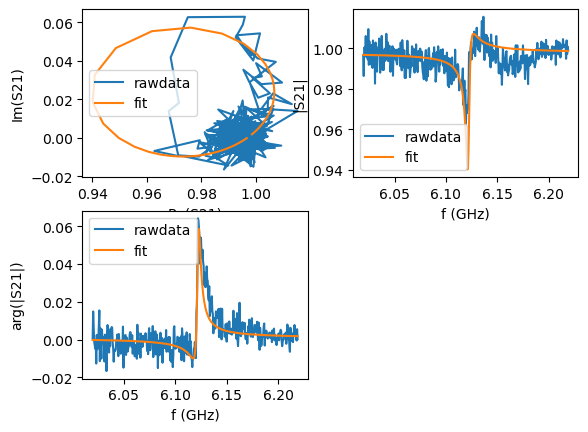

39
I1=-1.32 mA: f0=6122009618.589438 Hz, Ql=1.49e+03


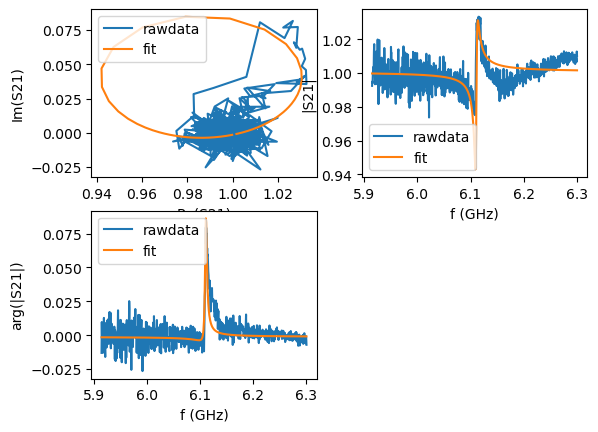

40
I1=-1.2 mA: f0=6110809718.957921 Hz, Ql=1.43e+03


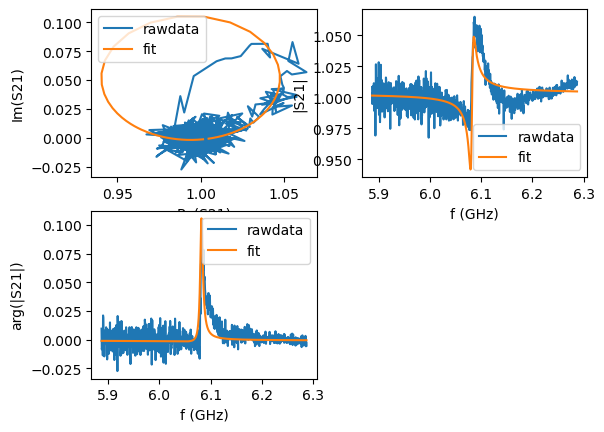

42
I1=-0.96 mA: f0=6081969103.047240 Hz, Ql=960


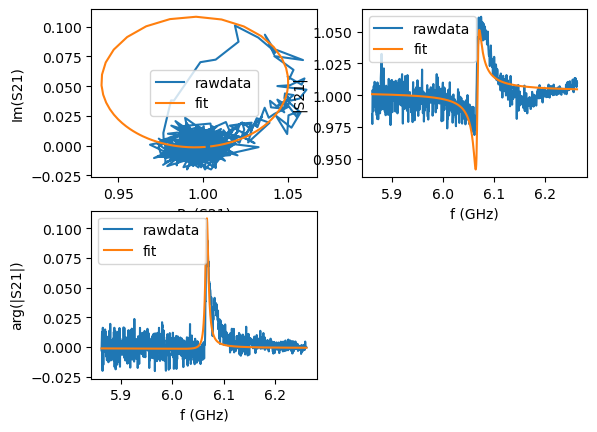

43
I1=-0.84 mA: f0=6067230799.571741 Hz, Ql=859


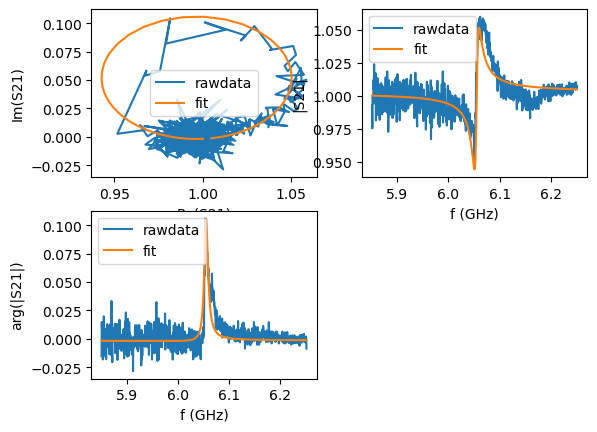

44
I1=-0.72 mA: f0=6055076136.725385 Hz, Ql=683


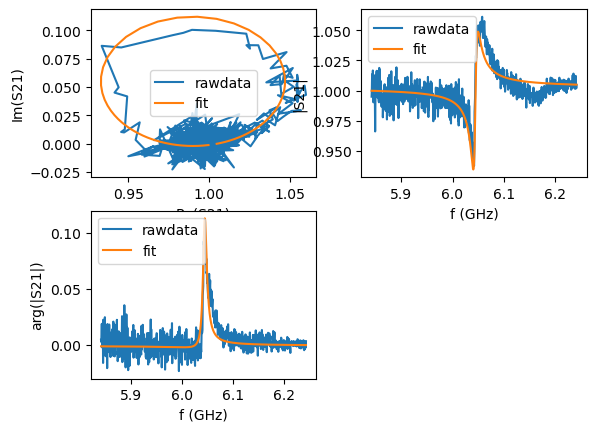

45
I1=-0.6 mA: f0=6044402636.592547 Hz, Ql=664


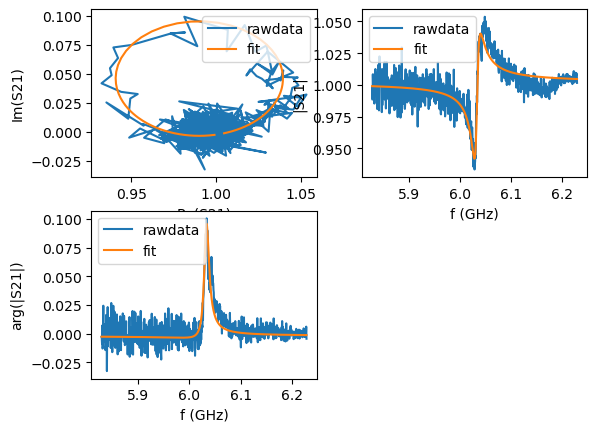

46
I1=-0.48 mA: f0=6033082326.648590 Hz, Ql=511


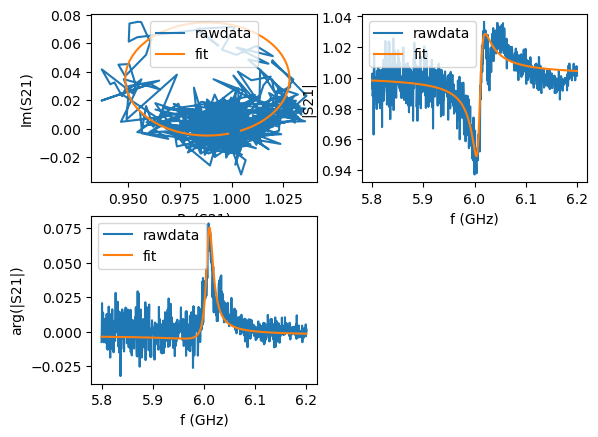

47
I1=-0.36 mA: f0=6009595366.240589 Hz, Ql=365


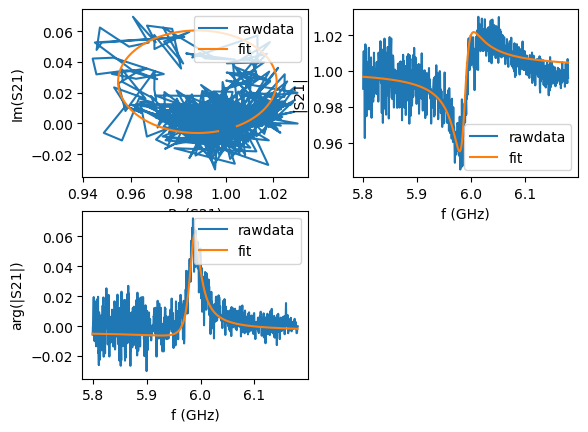

48
I1=-0.24 mA: f0=5987128513.167664 Hz, Ql=245


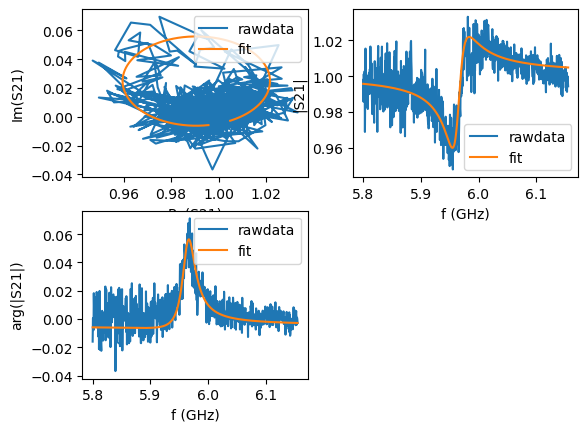

49
I1=-0.12 mA: f0=5964919846.895100 Hz, Ql=216


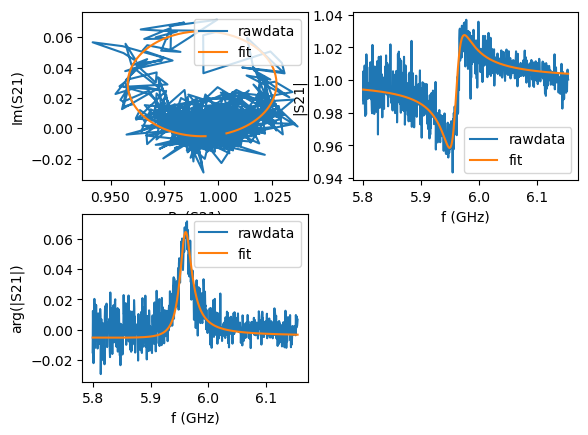

50
I1=0 mA: f0=5959813586.613518 Hz, Ql=236


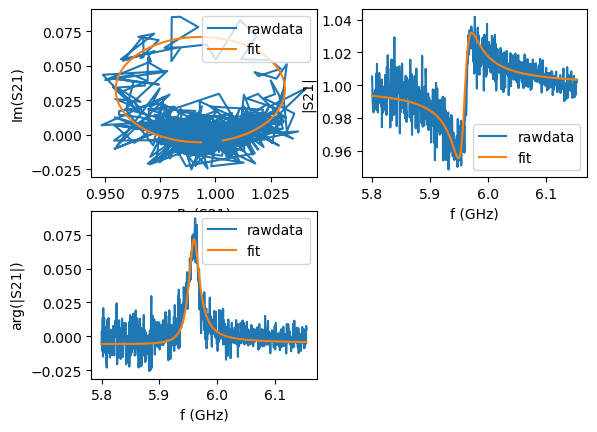

51
I1=0.12 mA: f0=5959301149.034851 Hz, Ql=262


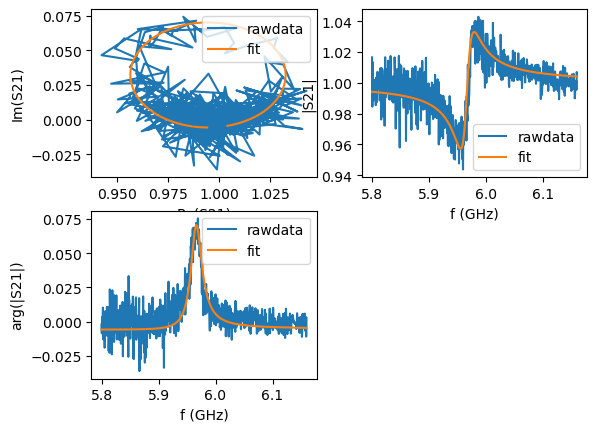

52
I1=0.24 mA: f0=5965978420.343788 Hz, Ql=252


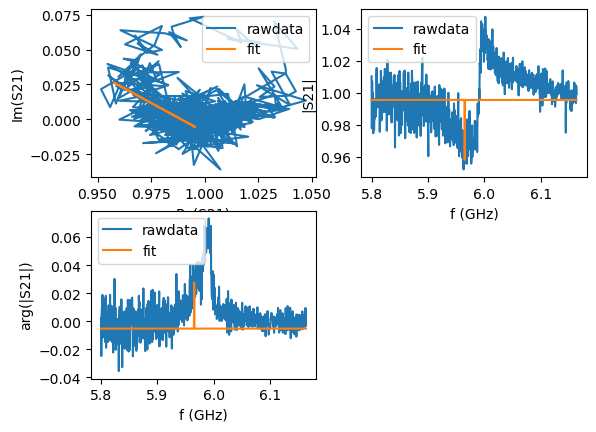

53
I1=0.36 mA: f0=5964999199.594654 Hz, Ql=-3.91e+06


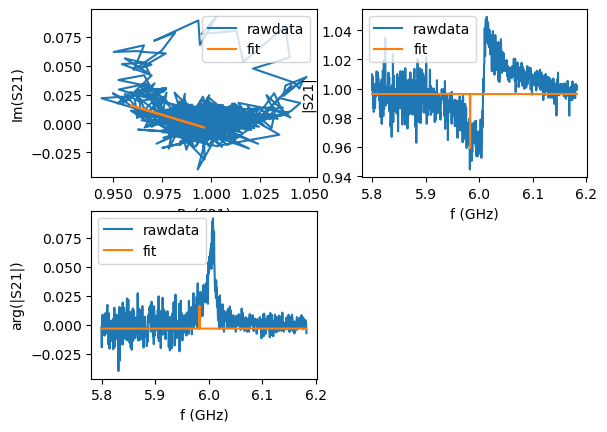

54
I1=0.48 mA: f0=5982999865.147792 Hz, Ql=-3.9e+07


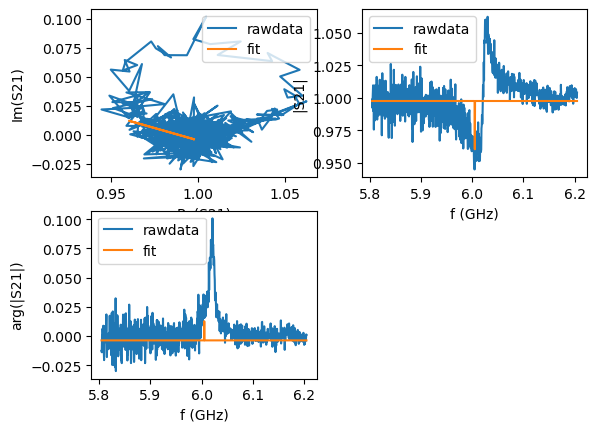

55
I1=0.6 mA: f0=6004999902.296243 Hz, Ql=-6.27e+07


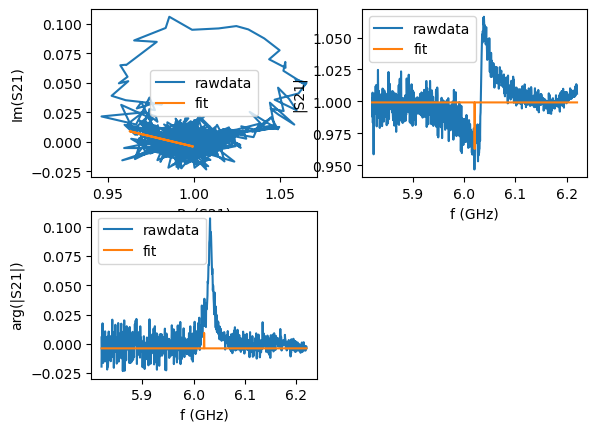

56
I1=0.72 mA: f0=6020499902.370895 Hz, Ql=-7.61e+07


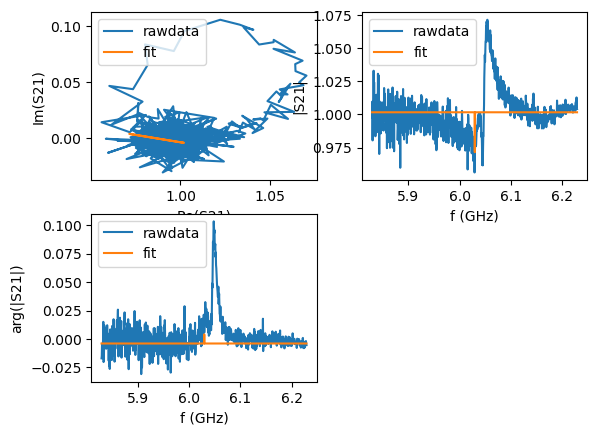

57
I1=0.84 mA: f0=6029499897.004995 Hz, Ql=-9.97e+07


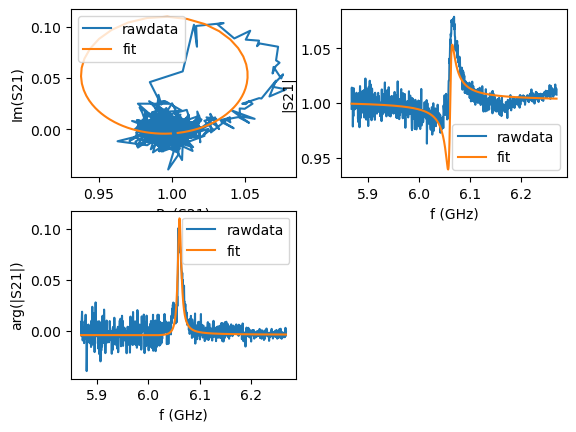

58
I1=0.96 mA: f0=6060676459.433911 Hz, Ql=743


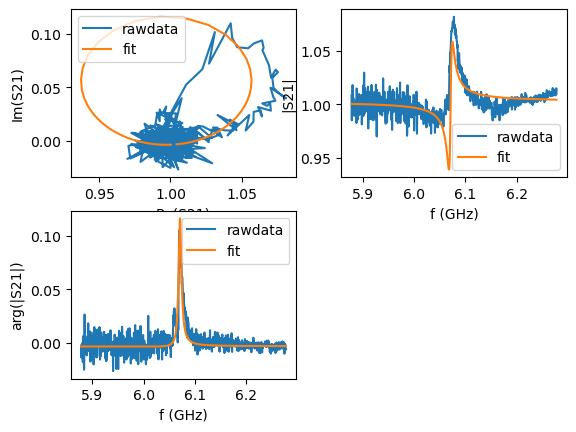

59
I1=1.08 mA: f0=6070972367.386058 Hz, Ql=918


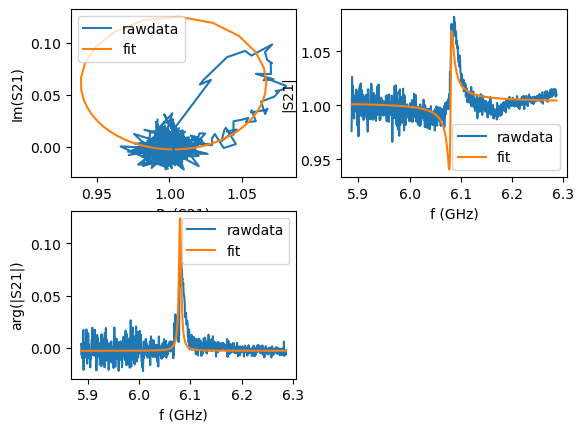

60
I1=1.2 mA: f0=6079916263.239311 Hz, Ql=1.16e+03


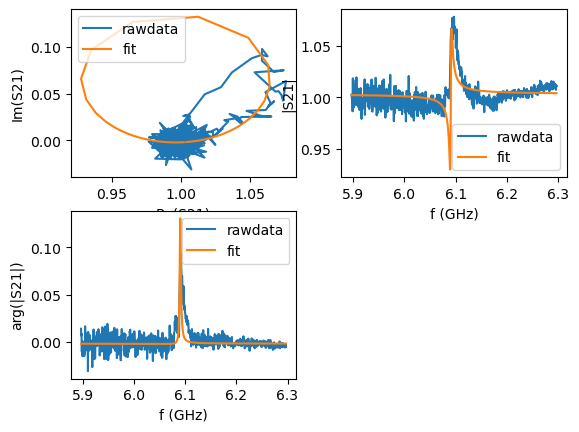

61
I1=1.32 mA: f0=6090761567.307271 Hz, Ql=2.19e+03


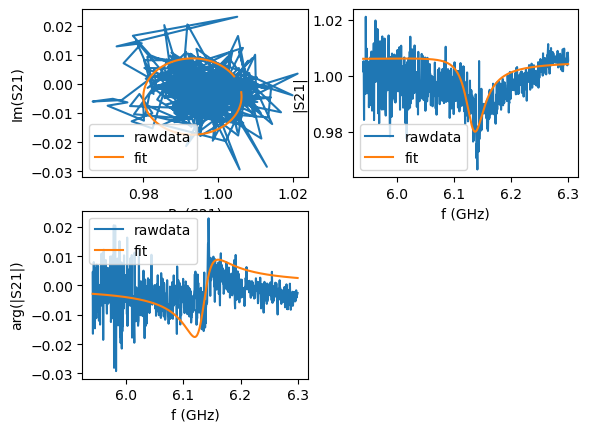

65
I1=1.8 mA: f0=6133794457.009192 Hz, Ql=155


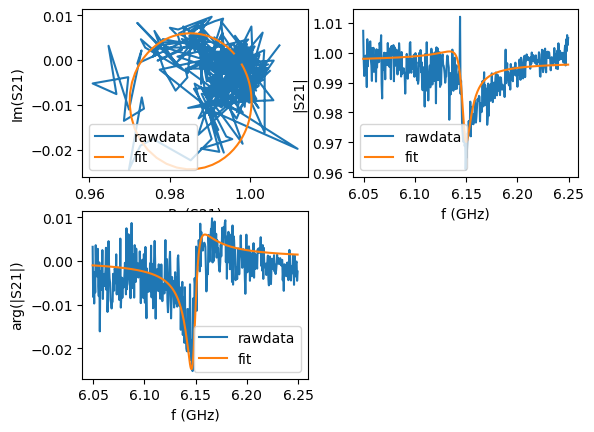

66
I1=1.92 mA: f0=6148296235.531605 Hz, Ql=591


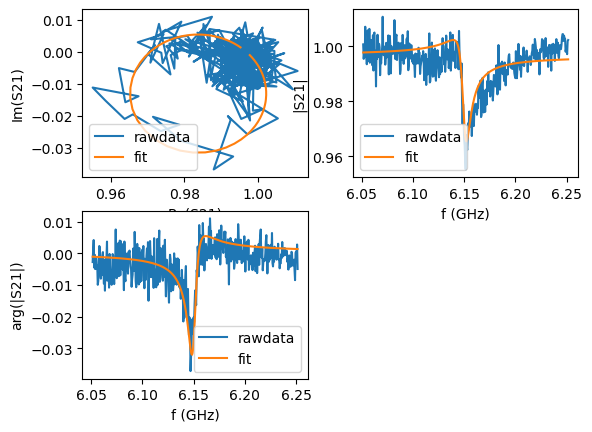

67
I1=2.04 mA: f0=6150193231.777611 Hz, Ql=651


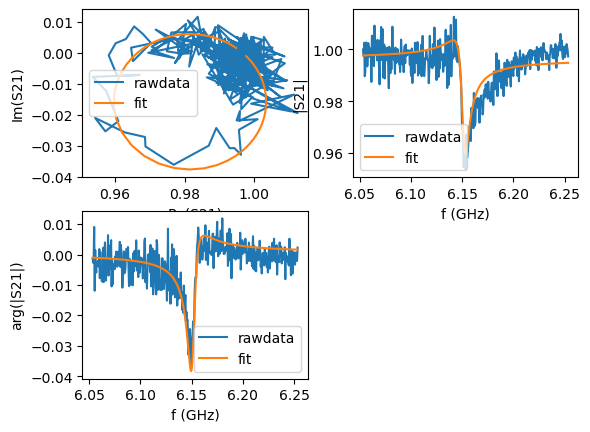

68
I1=2.16 mA: f0=6151208756.137137 Hz, Ql=695


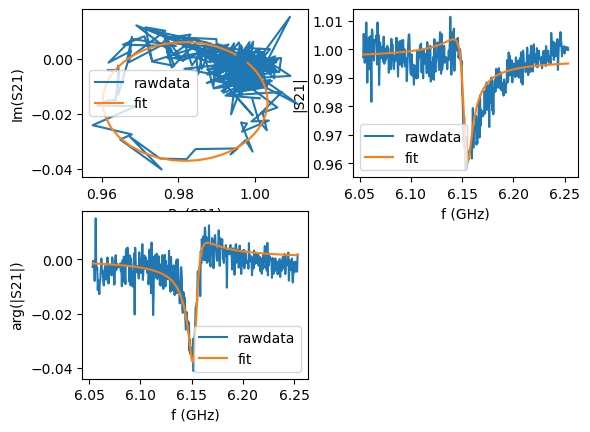

69
I1=2.28 mA: f0=6153069587.905151 Hz, Ql=605


In [71]:
for i in range(39, 70, 1):
        if fit_results_dict[i] is not None:
            ports_dict[i].plotall()
            print(i)
            print(f"I1={I1_full[i]:.3g} mA: f0={fit_results_dict[i]['fr']:.6f} Hz, Ql={fit_results_dict[i]['Ql']:.3g}")

In [58]:
import inspect
print(inspect.signature(circuit.notch_port.autofit))
print(inspect.getsource(circuit.notch_port.autofit))

(self, electric_delay: float | None = None, fcrop: tuple[float, float] | None = None, Ql_guess: float | None = None, fr_guess: float | None = None) -> None
    def autofit(
        self,
        electric_delay: float | None = None,
        fcrop: tuple[float, float] | None = None,
        Ql_guess: float | None = None,
        fr_guess: float | None = None,
    ) -> None:
        """
        automatic calibration and fitting
        electric_delay: set the electric delay manually
        fcrop = (f1,f2) : crop the frequency range used for fitting
        """
        assert self.f_data is not None, "No frequency data loaded"
        assert self.z_data_raw is not None, "No raw S-parameter data loaded"
        if fcrop is None:
            self._fid = np.ones(self.f_data.size, dtype=bool)
        else:
            f1, f2 = fcrop
            self._fid = np.logical_and(self.f_data >= f1, self.f_data <= f2)
        delay, amp_norm, alpha, fr, Ql, A2, frcal = self.do_calibration(
            

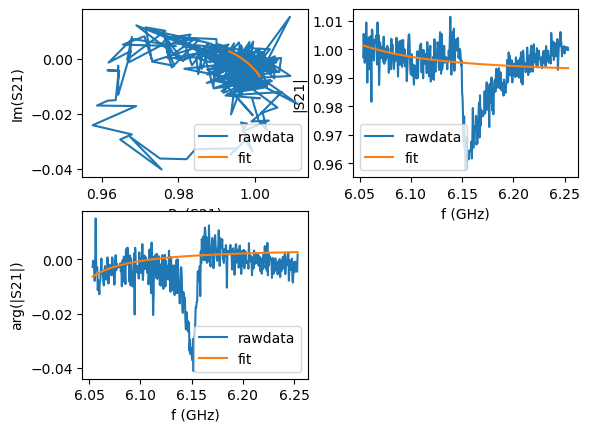

[ 9.93634674e-01  6.48245630e-11 -6.07284853e-02]


In [61]:
window_halfwidth = 100e6
lower_bound = f0_guess[i] - window_halfwidth
upper_bound = f0_guess[i] + window_halfwidth
mask = (Freq >= lower_bound) & (Freq <= upper_bound)
f_sub, s_sub = Freq[mask], S21_Complex_full[mask, i]   # same masking as your loop
p = circuit.notch_port(f_sub, s_sub)
p.autofit(electric_delay=0, fr_guess=f0_guess[60], Ql_guess = 500)
p.plotall()                      # look at the circle and the baseline normalization

# what does the internal skewed-Lorentzian stage say?
print(p._fit_skewed_lorentzian(f_sub, s_sub)[0:3])   # fr, Ql, ... compare to f0_guess[60]

In [33]:
import inspect
print(inspect.signature(circuit.notch_port.autofit))

(self, electric_delay: float | None = None, fcrop: tuple[float, float] | None = None, Ql_guess: float | None = None, fr_guess: float | None = None) -> None


In [103]:
print(sorted(fit_results_dict[0].keys()))

['Qc_dia_corr', 'Qi_dia_corr', 'Qi_dia_corr_err', 'Qi_no_corr', 'Qi_no_corr_err', 'Ql', 'Ql_err', 'absQc', 'absQc_err', 'chi_square', 'fr', 'fr_err', 'phi0', 'phi0_err', 'theta0']


In [17]:
import numpy as np

fr = np.full(len(fit_results_dict), np.nan)
Qi = np.full(len(fit_results_dict), np.nan)
Qc = np.full(len(fit_results_dict), np.nan)
Ql = np.full(len(fit_results_dict), np.nan)

for i, r in enumerate(fit_results_dict.values()):
    if r is None:
        continue
    fr[i] = r['fr']
    Qi[i] = r.get('Qi_dia_corr', r.get('Qi'))   # key names vary slightly by version — check port.fitresults.keys()
    Qc[i] = r.get('Qc_dia_corr', r.get('Qc'))
    Ql[i] = r['Ql']
    Ql[39] = Ql[38]
    Ql[43] = Ql[44]

In [18]:
for i in [0, 20]:
    r = fit_results_dict[i]
    print(i, {k: r[k] for k in ('fr','fr_err','Ql','Ql_err','phi0','phi0_err','theta0','chi_square')})

0 {'fr': 6215704744.005655, 'fr_err': 323754.57225095714, 'Ql': 275.24561702864736, 'Ql_err': 8.294005280983392, 'phi0': 1.4959776827822582, 'phi0_err': 0.02248236029196922, 'theta0': -1.645614970807535, 'chi_square': 4.9270018279553165e-05}
20 {'fr': 6187754524.395086, 'fr_err': 288969.3128330758, 'Ql': 451.6985773804432, 'Ql_err': 18.06233659290287, 'phi0': 1.2599877699403117, 'phi0_err': 0.03263289589678099, 'theta0': -1.8816048836494819, 'chi_square': 4.6921106405837056e-05}


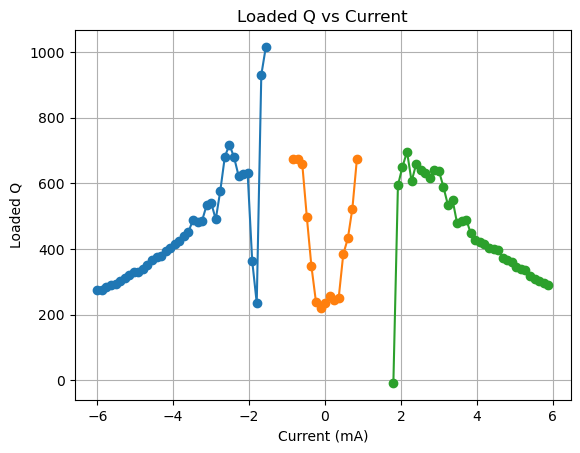

In [19]:
plt.plot(I1_full[0:38], Ql[0:38], 'o-')
plt.plot(I1_full[43:58], Ql[43:58], 'o-')
# plt.plot(I1_full[56:57], Ql[56:57], 'o-')
plt.plot(I1_full[65:100], Ql[65:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()

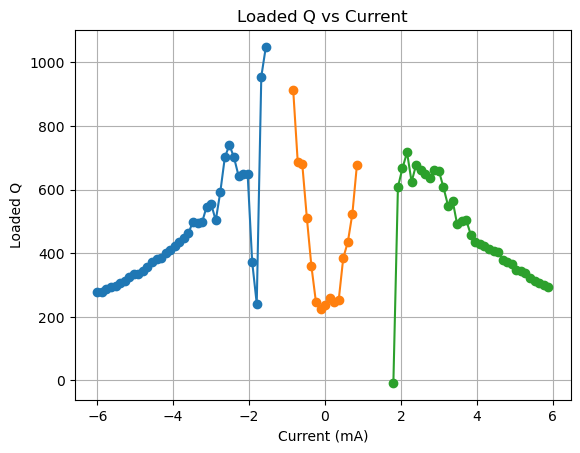

In [20]:
plt.plot(I1_full[0:38], Qi[0:38], 'o-')
plt.plot(I1_full[43:58], Qi[43:58], 'o-')
# plt.plot(I1_full[56:57], Ql[56:57], 'o-')
plt.plot(I1_full[65:100], Qi[65:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()

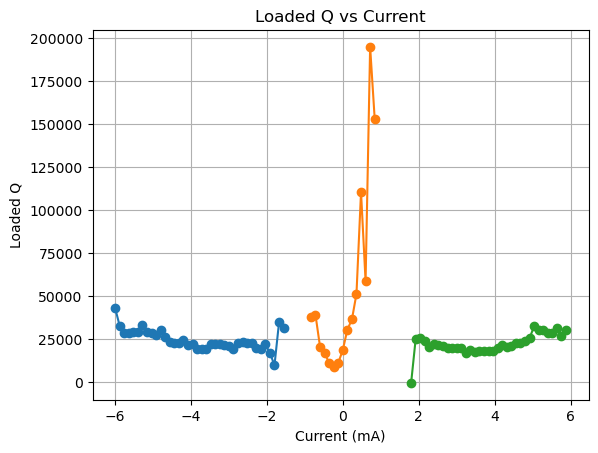

In [21]:
plt.plot(I1_full[0:38], Qc[0:38], 'o-')
plt.plot(I1_full[43:58], Qc[43:58], 'o-')
# plt.plot(I1_full[56:57], Ql[56:57], 'o-')
plt.plot(I1_full[65:100], Qc[65:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()

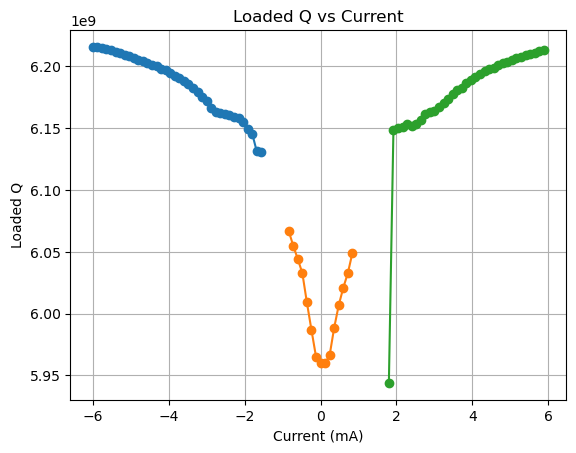

In [22]:
plt.plot(I1_full[0:38], fr[0:38], 'o-')
plt.plot(I1_full[43:58], fr[43:58], 'o-')
# plt.plot(I1_full[56:57], Ql[56:57], 'o-')
plt.plot(I1_full[65:100], fr[65:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()

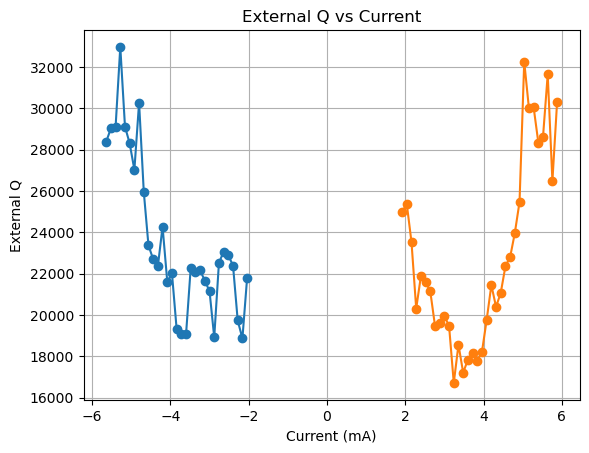

In [21]:
plt.plot(I1_full[3:34], Qc[3:34], 'o-')
# plt.plot(I1_full[43:52], Qc[43:52], 'o-')
# plt.plot(I1_full[56:57], Qc[56:57], 'o-')
plt.plot(I1_full[66:100], Qc[66:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('External Q')
plt.title('External Q vs Current')
plt.grid(True)
plt.show()

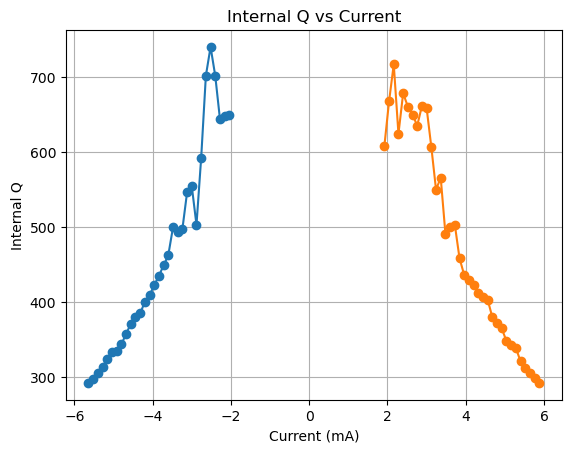

In [24]:
plt.plot(I1_full[3:34], Qi[3:34], 'o-')
# plt.plot(I1_full[43:52], Qc[43:52], 'o-')
# plt.plot(I1_full[56:57], Qc[56:57], 'o-')
plt.plot(I1_full[66:100], Qi[66:100], 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Internal Q')
plt.title('Internal Q vs Current')
plt.grid(True)
plt.show()

In [91]:
S21_Complex_2 = S21_Complex_full[:, 89:101]
I1_2 = I1_full[89:101]

# for i in range(S21_Complex_2.shape[1]):
#     print(i)
#     plt.plot(np.real(S21_Complex_2[:, i]), np.imag(S21_Complex_2[:, i]), 'o-')
#     plt.xlabel('Real')
#     plt.ylabel('Imaginary')
#     plt.title('S21 Complex Plane')
#     plt.show()


In [92]:
fit_results_dict_2 = {}
ports_dict_2 = {}   # optional, if you want to re-plot a specific trace later without refitting
window_halfwidth = 100e6 
for i in range(S21_Complex_2.shape[1]):
    mask = np.abs(Freq - f0_smooth[i]) < window_halfwidth
    f_sub = Freq[mask]
    s_sub = S21_Complex_2[mask, i]

    port_i = circuit.notch_port(f_sub, s_sub)
    try:
        port_i.autofit()
        fit_results_dict_2[i] = port_i.fitresults
        ports_dict_2[i] = port_i
    except Exception as e:
        print(f"I1={I1_2[i]:.3g} mA: fit failed ({e})")
        fit_results_dict_2[i] = None

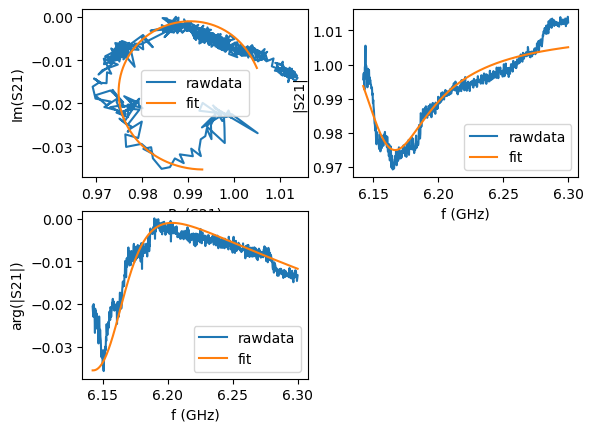

0
I1=5.46 mA: f0=6156469401.127153 Hz, Ql=98.2


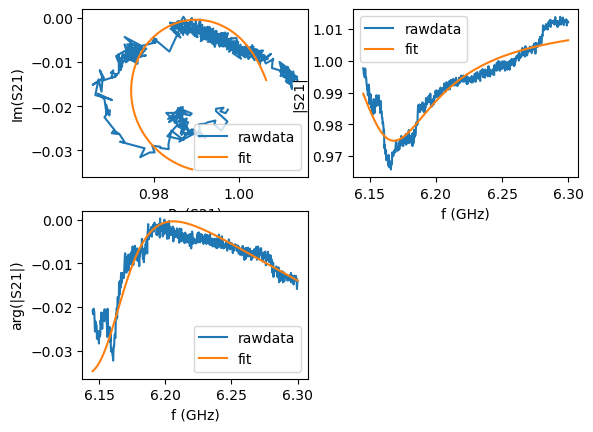

1
I1=5.6 mA: f0=6155770870.543033 Hz, Ql=83.6


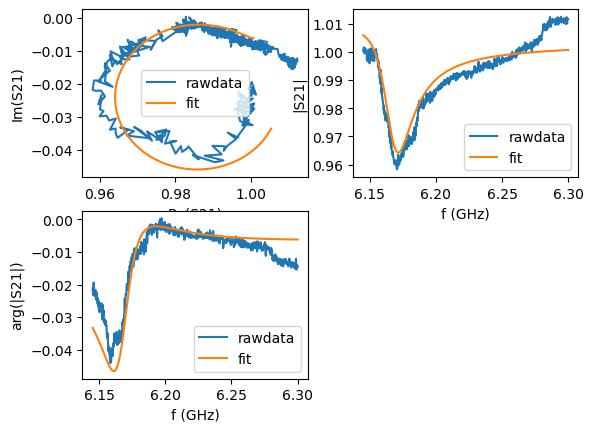

2
I1=5.74 mA: f0=6167296366.686216 Hz, Ql=241


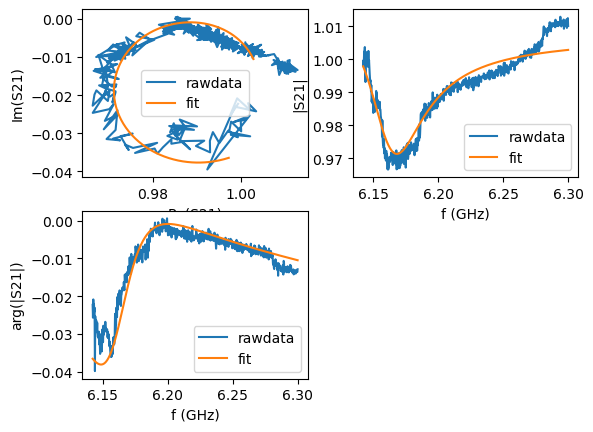

3
I1=5.88 mA: f0=6160330792.482904 Hz, Ql=126


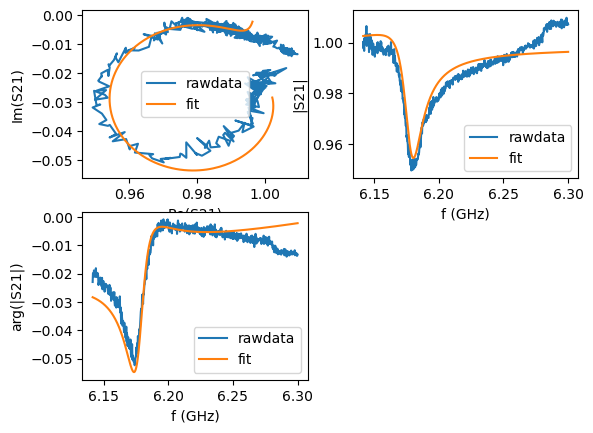

4
I1=6.02 mA: f0=6177619099.489537 Hz, Ql=375


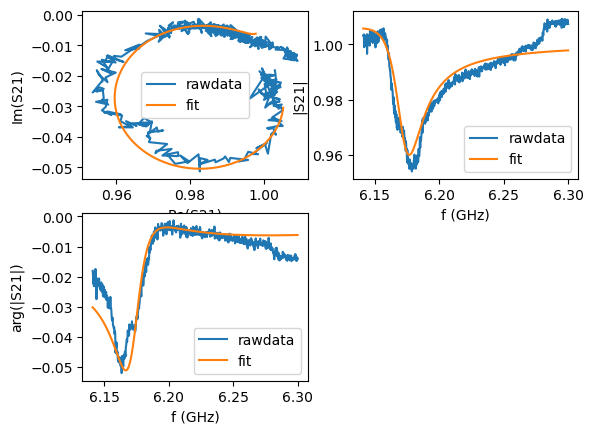

5
I1=6.16 mA: f0=6172431555.124295 Hz, Ql=253


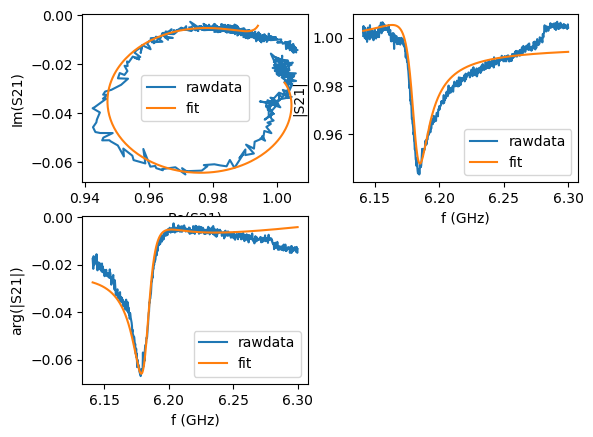

6
I1=6.3 mA: f0=6181795440.521768 Hz, Ql=402


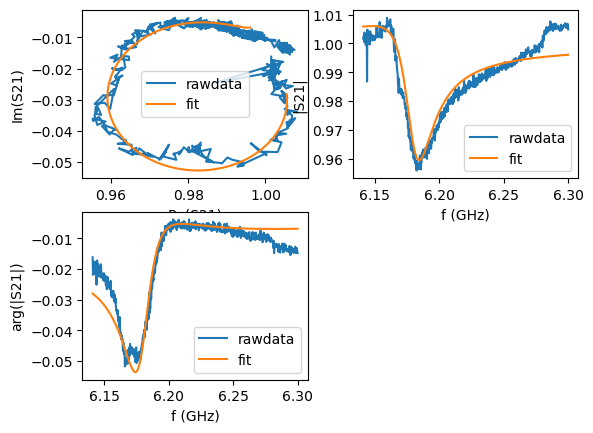

7
I1=6.44 mA: f0=6179404316.095573 Hz, Ql=245


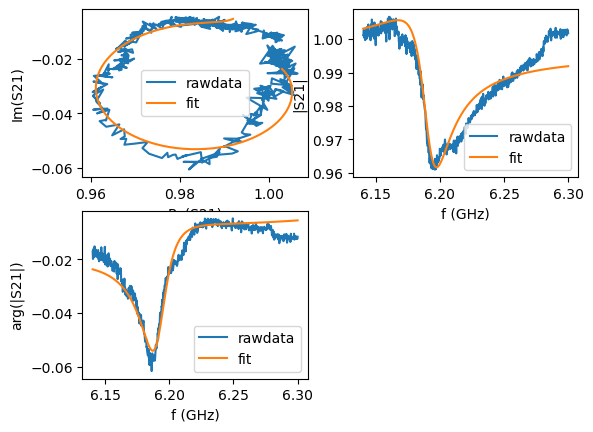

8
I1=6.58 mA: f0=6190878340.750670 Hz, Ql=249


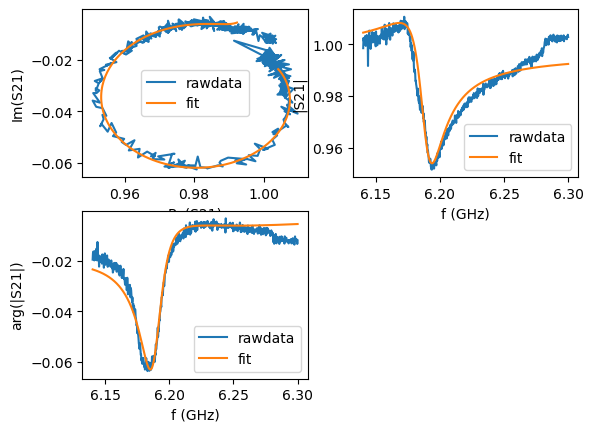

9
I1=6.72 mA: f0=6188361648.729506 Hz, Ql=295


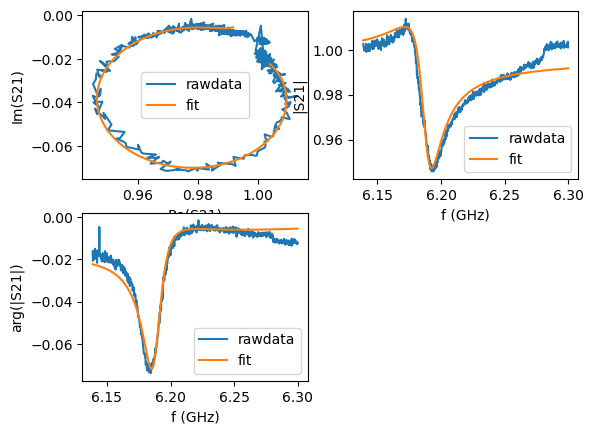

10
I1=6.86 mA: f0=6187627259.513644 Hz, Ql=346


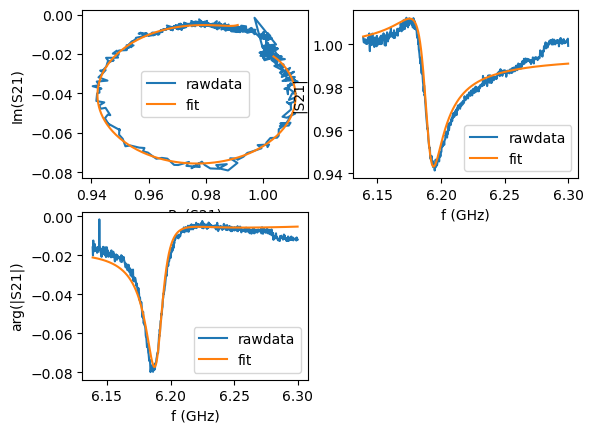

11
I1=7 mA: f0=6189469055.044045 Hz, Ql=382


In [93]:
for i in range(S21_Complex_2.shape[1]):
        if fit_results_dict_2[i] is not None:
            ports_dict_2[i].plotall()
            print(i)
            print(f"I1={I1_2[i]:.3g} mA: f0={fit_results_dict_2[i]['fr']:.6f} Hz, Ql={fit_results_dict_2[i]['Ql']:.3g}")

In [94]:
fr_2 = np.full(len(fit_results_dict_2), np.nan)
Qi_2 = np.full(len(fit_results_dict_2), np.nan)
Qc_2 = np.full(len(fit_results_dict_2), np.nan)
Ql_2 = np.full(len(fit_results_dict_2), np.nan)

for i, r in enumerate(fit_results_dict_2.values()):
    if r is None:
        continue
    fr_2[i] = r['fr']
    Qi_2[i] = r.get('Qi_dia_corr', r.get('Qi'))   # key names vary slightly by version — check port.fitresults.keys()
    Qc_2[i] = r.get('Qc_dia_corr', r.get('Qc'))
    Ql_2[i] = r['Ql']

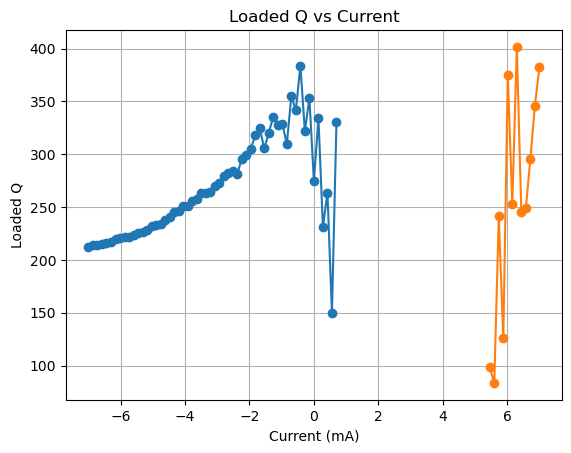

In [96]:
plt.plot(I1, Ql, 'o-')
plt.plot(I1_2, Ql_2, 'o-')
plt.xlabel('Current (mA)')
plt.ylabel('Loaded Q')
plt.title('Loaded Q vs Current')
plt.grid(True)
plt.show()